In [5]:
import importlib
import harmonic

importlib.reload(harmonic)
from harmonic import HarmonicOscillator

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import sys
from pathlib import Path

# Find harmonic.py in the current folder or its parent
folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent

sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})


def simulate(A=0.8, omega=1.0, dt=0.02, n=128, L=12, tmax=20):
    ho = HarmonicOscillator(boundary=(-L, L), n=n)
    x = ho.xi()
    times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

    energies, basis = ho.eigenstates()

    states = np.empty((len(times), n), dtype=complex)
    states[0] = basis[:, 0]

    for i in range(1, len(times)):
        states[i] = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=states[i-1],
            t0=times[i-1]
        )

    amplitudes = states @ basis.conj()
    E0 = np.abs(amplitudes)**2 @ energies

    return x, times, states, E0

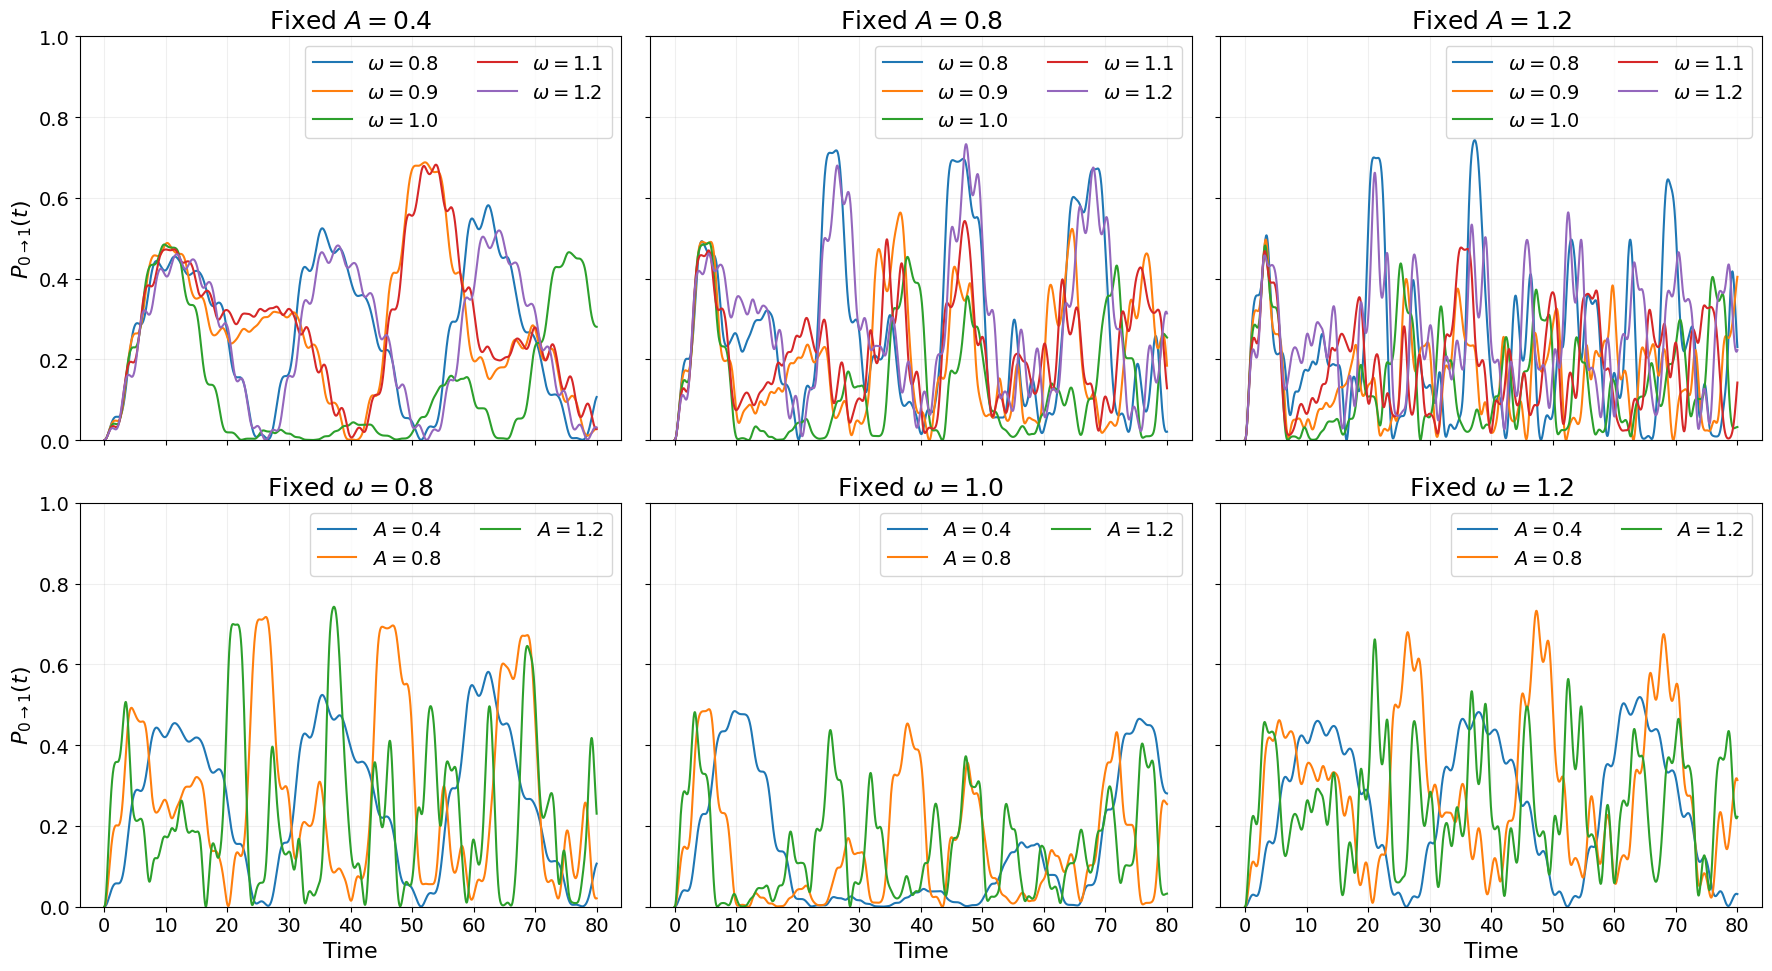

In [9]:
A_panels = [0.4, 0.8, 1.2]
A_curves = [0.4, 0.8, 1.2]

omega_panels = [0.8, 1.0, 1.2]
omega_curves = [0.8, 0.9, 1.0, 1.1, 1.2]

n = 128
L = 12
tmax = 80

# First excited state, using the same grid as the simulation
ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()
phi1 = basis[:, 1]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 10),
    sharex=True, sharey=True
)

# Top row: fix A, vary omega
for ax, A in zip(axes[0], A_panels):
    for omega in omega_curves:
        _, t, states, _ = simulate(
            A=A, omega=omega, n=n, L=L, tmax=tmax
        )

        P1 = np.abs(states @ phi1.conj())**2
        ax.plot(t, P1, label=rf"$\omega={omega:.1f}$")

    ax.set_title(rf"Fixed $A={A:.1f}$")

# Bottom row: fix omega, vary A
for ax, omega in zip(axes[1], omega_panels):
    for A in A_curves:
        _, t, states, _ = simulate(
            A=A, omega=omega, n=n, L=L, tmax=tmax
        )

        P1 = np.abs(states @ phi1.conj())**2
        ax.plot(t, P1, label=rf"$A={A:.1f}$")

    ax.set_title(rf"Fixed $\omega={omega:.1f}$")
    ax.set_xlabel("Time")

for ax in axes[:, 0]:
    ax.set_ylabel(r"$P_{0\to1}(t)$")

for ax in axes.flat:
    ax.set_ylim(0, 1)
    ax.legend(ncol=2)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

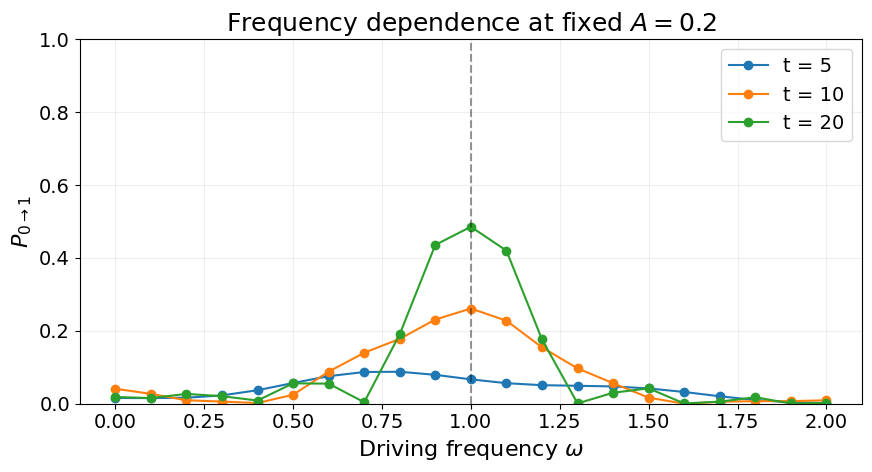

In [10]:
A = 0.2
n = 128
L = 12

omega_values = np.linspace(0, 2.0, 21)  # Spacing = 0.01
sample_times = [5, 10, 20]

ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()
phi1 = basis[:, 1]

probabilities = {t: [] for t in sample_times}

for omega in omega_values:
    _, times, states, _ = simulate(
        A=A, omega=omega,
        n=n, L=L,
        dt=0.02, tmax=max(sample_times)
    )

    P1 = np.abs(states @ phi1.conj())**2

    # Extract P1 at each selected time
    for t in sample_times:
        index = np.argmin(np.abs(times - t))
        probabilities[t].append(P1[index])

plt.figure(figsize=(9, 5))

for t in sample_times:
    plt.plot(omega_values, probabilities[t], "o-", label=f"t = {t}")

plt.axvline(1.0, color="black", linestyle="--", alpha=0.4)

plt.xlabel(r"Driving frequency $\omega$")
plt.ylabel(r"$P_{0\to1}$")
plt.title(rf"Frequency dependence at fixed $A={A}$")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()